In [1]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale']
df = df[['price', 'bedrooms', 'baths', 'Area Size']].dropna()

In [4]:
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

In [5]:
df = df.sample(n=100, random_state=42).reset_index(drop=True)

In [6]:
X = df[['price', 'bedrooms', 'baths', 'Area Size']]
X_scaled = StandardScaler().fit_transform(X)

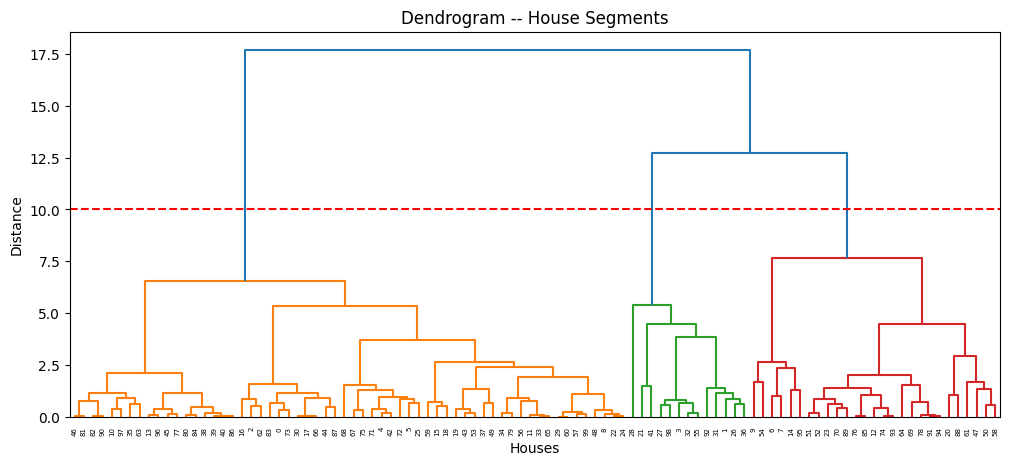

In [7]:
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(linked)
plt.title('Dendrogram -- House Segments')
plt.xlabel('Houses')
plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

In [8]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['HC_Cluster'] = hc.fit_predict(X_scaled)

In [9]:
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(2))

HC_Cluster
1    60
0    27
2    13
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0           26203703.70      5.52   5.52      10.22
1            9469316.67      2.87   2.80       4.87
2           73653846.15      6.08   6.92       1.28
